# Evaluation of the expert pools

AUROC of every expert (rows) on every generator's images (columns), for the ResNet pool and the CLIP pool.
Both read the saved expert scores (`resnet/score.py`, `clip/score.py`), so run those notebooks first. See `common/evaluation.py`.

- **Diagonal ≈ 1.0:** each expert detects its own generator(s).
- **Siblings high:** SD ↔ wukong, ADM → glide / BigGAN.
- **Off-diagonal:** how well an expert transfers to generators it never saw.

A low diagonal means training went wrong. *Everything* ≈ 1.0 points to a shortcut (image size or JPEG traces).
`test` is not looked at.

In [2]:
import sys
sys.path.insert(0, "..")  # repo root, so `clip`, `common`, `data` and `resnet` are importable

from clip.score import SCORES_NAME as CLIP_SCORES
from common.evaluation import cross_auroc, plot_cross_auroc
from resnet.score import feature_name

ARCH = "resnet18"  # the ResNet experts to evaluate
LIMIT = None  # the limit of a ResNet test run, None for the full run
POOL = "meta_val"

W1103 20:48:21.414000 1459 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## ResNet experts

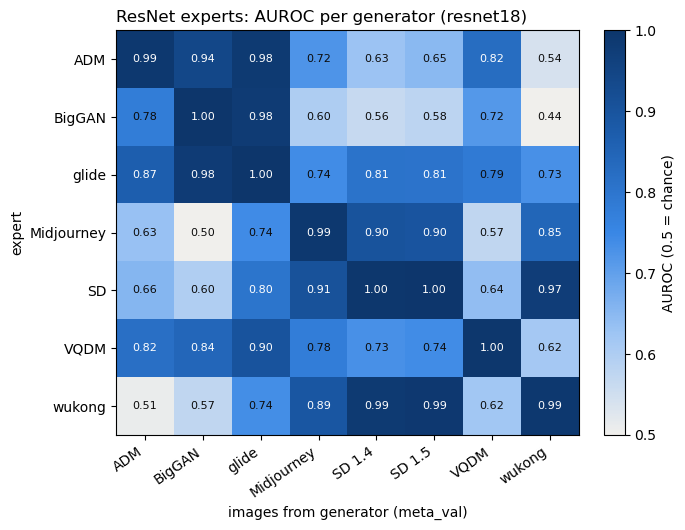

,ADM,BigGAN,glide,Midjourney,stable_diffusion_v_1_4,stable_diffusion_v_1_5,VQDM,wukong
ADM,0.991,0.943,0.985,0.724,0.627,0.650,0.824,0.540
BigGAN,0.779,0.999,0.982,0.600,0.563,0.579,0.715,0.435
glide,0.867,0.980,1.000,0.740,0.808,0.806,0.786,0.732
Midjourney,0.631,0.495,0.740,0.990,0.903,0.898,0.573,0.846
SD,0.655,0.597,0.802,0.908,0.995,0.997,0.640,0.974
VQDM,0.817,0.844,0.901,0.776,0.732,0.738,0.996,0.615
wukong,0.509,0.573,0.736,0.892,0.985,0.989,0.618,0.990


In [3]:
resnet_table = cross_auroc(feature_name(ARCH, LIMIT), POOL)
plot_cross_auroc(resnet_table, f"ResNet experts: AUROC per generator ({ARCH})", POOL)
resnet_table.round(3)

## CLIP experts

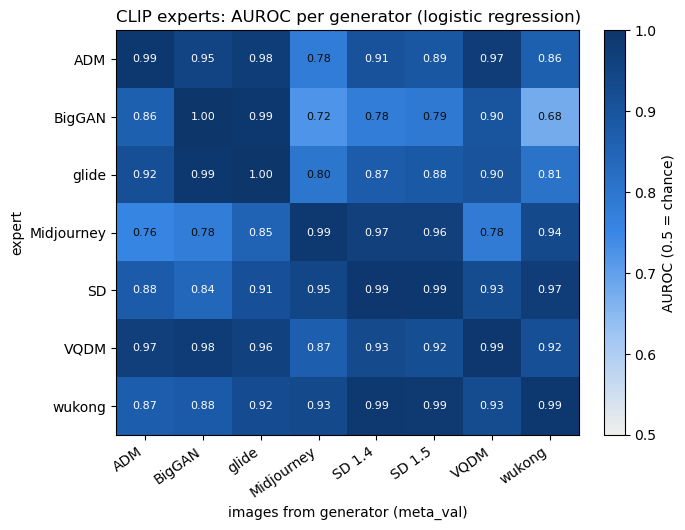

,ADM,BigGAN,glide,Midjourney,stable_diffusion_v_1_4,stable_diffusion_v_1_5,VQDM,wukong
ADM,0.992,0.954,0.976,0.781,0.906,0.890,0.973,0.862
BigGAN,0.862,1.000,0.991,0.723,0.777,0.790,0.899,0.677
glide,0.916,0.992,0.998,0.799,0.875,0.884,0.904,0.810
Midjourney,0.755,0.777,0.854,0.990,0.966,0.963,0.782,0.936
SD,0.876,0.840,0.911,0.947,0.993,0.992,0.927,0.974
VQDM,0.967,0.977,0.962,0.866,0.932,0.919,0.992,0.916
wukong,0.871,0.879,0.924,0.935,0.989,0.988,0.927,0.991


In [4]:
clip_table = cross_auroc(CLIP_SCORES, POOL)
plot_cross_auroc(clip_table, "CLIP experts: AUROC per generator (logistic regression)", POOL)
clip_table.round(3)